# Proyecto: Venteo y Quema de Gas

**Pregunta de investigación:** ¿Qué factores (estado, tipo de tierra, estación, región offshore y período) están **asociados** con una mayor proporción o probabilidad de gas venteado o quemado frente a gas vendido?

> Nota: el objetivo es identificar **asociaciones** en datos observacionales. No se afirma causalidad. (Consultar eso a la profe)

**Fuente:** `OGORBcsv.csv` (producción y disposición de hidrocarburos, Mensual, 2015-01 a 2025-05).

## Parte 1 - Carga de librerias y Dataset

### 1.1 - Librerias

In [87]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import optuna

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, learning_curve

from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, accuracy_score, f1_score, recall_score)


pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42 #Fija una semilla aleatoreia para que las operaciones que usen aletoriedad den resultados reproducible
#Investigamos y es "buena practica hacer esto". Consultar si realmente produce un cambio considerable sacar la linea


### 1.2 - Carga y presentacion del dataset

In [88]:
RUTA = 'OGORBcsv.csv'
df = pd.read_csv(RUTA) 
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (470830, 11)


,Production Date,Land Class,Land Category,State,County,FIPS Code,Offshore Region,Commodity,Disposition Code,Disposition Description,Volume
0,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0
1,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,"14,508,756"
2,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,"1,207,520"
3,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,"487,324"
4,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,"114,808"


In [89]:
df.tail()

,Production Date,Land Class,Land Category,State,County,FIPS Code,Offshore Region,Commodity,Disposition Code,Disposition Description,Volume
470825,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),62,Vented Gas Well Gas - Royalty Not Due,0
470826,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),66,Flared Oil Well Gas - Royalty Due,0
470827,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),67,Flared Gas Well Gas - Royalty Due,0
470828,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),68,Vented Oil Well Gas - Royalty Due,0
470829,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),69,Vented Gas Well Gas - Royalty Due,0


### 1.3 - Normalizar nombres de las columnas

In [90]:
# Normalización de nombres de columnas
df.columns = [re.sub(r'\s+', '_', c.strip().lower()) for c in df.columns]
print(df.columns.tolist())

['production_date', 'land_class', 'land_category', 'state', 'county', 'fips_code', 'offshore_region', 'commodity', 'disposition_code', 'disposition_description', 'volume']


In [91]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 470830 entries, 0 to 470829
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   production_date          470830 non-null  str    
 1   land_class               470830 non-null  str    
 2   land_category            470830 non-null  str    
 3   state                    454200 non-null  str    
 4   county                   454200 non-null  str    
 5   fips_code                454200 non-null  float64
 6   offshore_region          10196 non-null   str    
 7   commodity                470830 non-null  str    
 8   disposition_code         470830 non-null  int64  
 9   disposition_description  470830 non-null  str    
 10  volume                   470830 non-null  str    
dtypes: float64(1), int64(1), str(9)
memory usage: 74.6 MB


Observo que hay un total de 470830 filas y 11 columnas

La mayoria variables categoricas a excepcion de flips code y disposition code. Tambien me doy cuenta que hay un error respecto a los valores de volumen.

Estos se muestran como "str" cuando son valores numericos. Esto se debe a que hay "," en los valores. Es necesario solucionar esto

## Parte 2 - Analisis de datos


### 2.1 - Problema 1: formato numérico de `volume`
Comprobamos el formato real y la conversión antes de aplicarla.

In [92]:
#Me traico 5 valores para comprobar esto de "," en la unidad de volumen
print('Ejemplos con separador de miles:')
print(df.loc[df['volume'].str.contains(','), 'volume'].head(5).tolist())

#Cuenta los valores que esten vacios o solo contienen espacios. Valores como NaN o 0 no se cuentan
print('\nValores vacíos en volume:', (df['volume'].str.strip() == '').sum())

#Cambio el "," del dataset y lo pego en la misma columna
df['volume'] = pd.to_numeric(df['volume'].str.replace(',', '', regex=False), errors='coerce')

#Veo valores negativos
print('Valores negativos:', (df['volume'] < 0).sum())

print('Verificación del tipo de dato:', df['volume'].dtype)


Ejemplos con separador de miles:
['14,508,756', '1,207,520', '487,324', '114,808', '1,160']

Valores vacíos en volume: 0
Valores negativos: 13036
Verificación del tipo de dato: int64


### 2.2 - Unidades físicas distintas (gas en Mcf vs. petróleo en bbl)
Verificamos que `commodity` separe ambas unidades. **No se suman volúmenes de gas y petróleo.**

In [93]:
# Se usa la columna 'volume' ya convertida a numérico
print(df.groupby('commodity')['volume'].agg(['count', 'sum']))
print('\nLa suma de gas y petróleo NO es una magnitud válida: se trabaja solo con Gas (Mcf).')

            count          sum
commodity                     
Gas (Mcf)  235415  51194121625
Oil (bbl)  235415  11224187465

La suma de gas y petróleo NO es una magnitud válida: se trabaja solo con Gas (Mcf).


### 2.3 - Problema 3: formato de `production_date`
El formato es `MM/DD/YYYY` con día siempre 01. Verificamos antes de convertir.

In [94]:
# 1) Patrón de formato (sin cambios)
print('Formatos únicos (patrón):', df['production_date'].str.replace(r'\d', '9', regex=True).unique())

# 2) Parsear primero, sin modificar el dataframe todavía
fechas = pd.to_datetime(df['production_date'], format='%m/%d/%Y', errors='coerce')

print('Fechas no interpretables:', fechas.isna().sum())

# 3) Verificar el día real
print('Días distintos de 1:', (fechas.dt.day != 1).sum())
print(fechas.dt.day.value_counts())

# 4) Verificar la cobertura mensual
print('Meses distintos:', fechas.dt.to_period('M').nunique())
print(fechas.dt.month.value_counts().sort_index())

# 5) Asignar al dataframe
df['production_date'] = fechas
print('Rango:', df['production_date'].min().date(), '->', df['production_date'].max().date())

Formatos únicos (patrón): <ArrowStringArray>
['99/99/9999']
Length: 1, dtype: str
Fechas no interpretables: 0
Días distintos de 1: 0
production_date
1    470830
Name: count, dtype: int64
Meses distintos: 125
production_date
1     41384
2     41448
3     41534
4     41510
5     41224
6     37798
7     37650
8     37802
9     37606
10    37746
11    37636
12    37492
Name: count, dtype: int64
Rango: 2015-01-01 -> 2025-05-01


### 2.4 - Problema 4: códigos de disposición
Construimos la tabla de correspondencia **antes** de sumar nada.

Clasificación adoptada (documentada en el informe):
- **Venta comercial (gas):** 01, 04, 05, 06, 09, 07, 15, 43.
- **Venteo:** 61, 62, 63, 68, 69 (*Vented*).
- **Quema / flaring:** 21, 22, 33, 66, 67 (*Flared*).
- **Otros destinos internos o contables** (11 transferido a instalación, 20 uso en lugar, 14 inyección, 42 ajustes, 25 buy-back, etc.): **no son venta ni pérdida**, se excluyen.

In [95]:
relacion = (
    df[['disposition_code', 'disposition_description']]
    .drop_duplicates()
    .sort_values(['disposition_code', 'disposition_description'])
    .reset_index(drop=True)
)

relacion

,disposition_code,disposition_description
0,1,Sales-Royalty Due-MEASURED
1,3,Load Oil
2,4,Sales-Royalty Due-Not Measured
3,5,"Sales-Royalty Not Due, Recovered Injection-MEA..."
4,6,Sales-Non-Hydrocarbon Gas
5,7,Condensate Sales-Royalty Due-MEASURED
6,8,Spilled and/or Lost-Avoidable-Royalty Due
7,9,Sales-Royalty Not Due-MEASURED
8,10,Produced into Inventory Prior to Sales
9,11,Transferred to Facility


In [96]:
df_gas = df.loc[df['commodity'].eq('Gas (Mcf)')].copy()

descripcion = (
    df_gas['disposition_description']
    .fillna('')
    .astype('string')
    .str.strip()
)

coincidencias = pd.DataFrame({
    'Sales': descripcion.str.contains(
        r'\b(sale|sales|sold)\b', case=False, na=False
    ),
    'Vented': descripcion.str.contains(
        r'\b(vent|vented|venting)\b', case=False, na=False
    ),
    'Flared': descripcion.str.contains(
        r'\b(flare|flared|flaring)\b', case=False, na=False
    )
}, index=df_gas.index)

df_gas['tipo_disposicion'] = np.select(
    [
        coincidencias['Sales'] & coincidencias.sum(axis=1).eq(1),
        coincidencias['Vented'] & coincidencias.sum(axis=1).eq(1),
        coincidencias['Flared'] & coincidencias.sum(axis=1).eq(1)
    ],
    ['Sales', 'Vented', 'Flared'],
    default='Revisar'
)

tabla_tipos = (
    df_gas.groupby(
        ['tipo_disposicion', 'disposition_code', 'disposition_description'],
        dropna=False
    )
    .size()
    .reset_index(name='registros')
    .sort_values(['tipo_disposicion', 'disposition_code'])
    .reset_index(drop=True)
)

tabla_tipos

C:\Users\Alam\AppData\Local\Temp\ipykernel_2036\3376308364.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  'Sales': descripcion.str.contains(
C:\Users\Alam\AppData\Local\Temp\ipykernel_2036\3376308364.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  'Vented': descripcion.str.contains(
C:\Users\Alam\AppData\Local\Temp\ipykernel_2036\3376308364.py:17: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  'Flared': descripcion.str.contains(


,tipo_disposicion,disposition_code,disposition_description,registros
0,Flared,21,Flared Oil Well Gas - Royalty Not Due,8986
1,Flared,22,Flared Gas Well Gas - Royalty Not Due,4567
2,Flared,33,Flared Gas - Royalty Due,2884
3,Flared,66,Flared Oil Well Gas - Royalty Due,2445
4,Flared,67,Flared Gas Well Gas - Royalty Due,572
5,Revisar,3,Load Oil,90
6,Revisar,8,Spilled and/or Lost-Avoidable-Royalty Due,1206
7,Revisar,11,Transferred to Facility,17465
8,Revisar,12,Transferred to Facility-Returned to L/A,1496
9,Revisar,13,Transferred from Facility,5264


In [97]:
#Creo las columnas
VENTA = [1, 4, 5, 6, 7, 9, 15, 43]
VENTEO = [61, 62, 63, 68, 69]
QUEMA = [21, 22, 33, 66, 67]

#Creo una copia con el df original y creo otro llamado gas. Este es el que vamos a trabajar
gas = df[df['commodity'] == 'Gas (Mcf)'].copy()

#Defino la funcion
def categorizar(c):
    if c in VENTA:  return 'venta'
    if c in VENTEO: return 'venteo'
    if c in QUEMA:  return 'quema'
    return 'otro'

#Agrego una columna "categoria" para diferenciar los tipos de disposicion
gas['categoria'] = gas['disposition_code'].map(categorizar)

#Creo la tabla agrupando los valores que necesitamos
tabla_codigos = (gas.groupby(['disposition_code', 'disposition_description', 'categoria'])
                    .agg(registros=('volume', 'size'), volumen_mcf=('volume', 'sum'))
                    .reset_index())

#Ordeno la tabla
orden = ['venta', 'venteo', 'quema', 'otro']

tabla_codigos['categoria'] = pd.Categorical(
    tabla_codigos['categoria'],
    categories=orden,
    ordered=True
)

tabla_codigos = tabla_codigos.sort_values(
    ['categoria', 'disposition_code']
).reset_index(drop=True)


tabla_codigos

,disposition_code,disposition_description,categoria,registros,volumen_mcf
0,1,Sales-Royalty Due-MEASURED,venta,31512,12783398822
1,4,Sales-Royalty Due-Not Measured,venta,3477,31071152
2,5,"Sales-Royalty Not Due, Recovered Injection-MEA...",venta,377,119447925
3,6,Sales-Non-Hydrocarbon Gas,venta,847,2951838075
4,7,Condensate Sales-Royalty Due-MEASURED,venta,386,0
5,9,Sales-Royalty Not Due-MEASURED,venta,1548,1676110371
6,15,Sales-Buy-Back-Measured-Royalty Not Due,venta,1831,1334022108
7,43,Sales-Royalty Not Due-FMP Not Assigned,venta,39,1254
8,61,Vented Oil Well Gas - Royalty Not Due,venteo,4400,23170382
9,62,Vented Gas Well Gas - Royalty Not Due,venteo,3935,14168710


### 2.5 - Resumen de todas las correcciones

In [98]:

informe = pd.DataFrame([
    ['volume', 'Texto con comas de miles', 'Conversión numérica tras quitar comas',
     f"{len(df):,} registros", f"No convertibles: {df['volume'].isna().sum()}"],

    ['Unidades', 'Gas (Mcf) y Petróleo (bbl) mezclados', 'Filtro solo Gas (Mcf)',
     f"{(df['commodity']!='Gas (Mcf)').sum():,} petróleo excluido", 'Sin suma cruzada'],

    ['production_date', 'MM/DD/YYYY, día 01', 'pd.to_datetime con formato explícito',
     f"{df['production_date'].isna().sum()} no válidas", 'Rango 2015-01 a 2025-05'],

    ['disposition_code', '33 códigos', 'Tabla de correspondencia documentada',
     f"{gas['categoria'].value_counts().get('otro', 0):,} de gas excluidos (otros destinos)",
     'Solo venta/venteo/quema en el análisis'],

], columns=['Problema', 'Diagnóstico', 'Corrección', 'Registros afectados', 'Validación'])

informe

,Problema,Diagnóstico,Corrección,Registros afectados,Validación
0,volume,Texto con comas de miles,Conversión numérica tras quitar comas,"470,830 registros",No convertibles: 0
1,Unidades,Gas (Mcf) y Petróleo (bbl) mezclados,Filtro solo Gas (Mcf),"235,415 petróleo excluido",Sin suma cruzada
2,production_date,"MM/DD/YYYY, día 01",pd.to_datetime con formato explícito,0 no válidas,Rango 2015-01 a 2025-05
3,disposition_code,33 códigos,Tabla de correspondencia documentada,"166,451 de gas excluidos (otros destinos)",Solo venta/venteo/quema en el análisis


## Parte 3 - Limpieza y preparacion del dataset

- Se trabaja solo con gas.
- Se usan los registros venta, venteo y quema. Los demás destinos se excluyen.
- Los valores negativos de `volume` se **truncan a cero** solo para el cálculo de proporciones de disposición (representan reversiones y no volumen vendido/perdido). Se documenta.
- Se revisan duplicados y valores faltantes en las variables clave.

### 3.1 - Limpio el dataset
Excluyos los datos del dataset que no vamos a usar. Para ello creamos otro dataset llamado gas_limpio.

Basicamente saco las filas que no vamos a usar

In [99]:
#Creo una nueva copia con el dataframe que vamos a trabajar
gas_limpio = gas[gas['categoria'].isin(['venta', 'venteo', 'quema'])].copy()
#Una alternativa a esto es trabajar con el mismo df: gas pero haciendo drop de las filas con categoria: otros
#Con isin me devuelve True si la categoria es correcta y lo copia

#Creo una nueva columna "Perdida" para considerar los valores de venteo y quema
gas_limpio['perdida'] = gas_limpio['categoria'].isin(['venteo', 'quema']).astype(int)

#Reseteo el indice
gas_limpio.reset_index(drop=True, inplace=True)
gas_limpio.head()


,production_date,land_class,land_category,state,county,fips_code,offshore_region,commodity,disposition_code,disposition_description,volume,categoria,perdida
0,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0,venta,0
1,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,14508756,venta,0
2,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,1207520,venta,0
3,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,487324,venta,0
4,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,114808,venta,0


### 3.2 - Valores duplicados 

In [100]:
#Comparo y verifico si hay algun valor duplicado
print('Registros de gas totales:', len(gas)) 
print('Registros en el análisis:', len(gas_limpio))
print('Duplicados exactos en el df limpio:', gas_limpio.duplicated().sum())
#No hay valores duplicados

Registros de gas totales: 235415
Registros en el análisis: 68964
Duplicados exactos en el df limpio: 0


In [101]:
gas_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 68964 entries, 0 to 68963
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   production_date          68964 non-null  datetime64[us]
 1   land_class               68964 non-null  str           
 2   land_category            68964 non-null  str           
 3   state                    65351 non-null  str           
 4   county                   65351 non-null  str           
 5   fips_code                65351 non-null  float64       
 6   offshore_region          2077 non-null   str           
 7   commodity                68964 non-null  str           
 8   disposition_code         68964 non-null  int64         
 9   disposition_description  68964 non-null  str           
 10  volume                   68964 non-null  int64         
 11  categoria                68964 non-null  str           
 12  perdida                  68964 non-null  in

### 3.3 - Valores sin aporte de informacion

Aca lo que busco ver es la cantidad de informacion que tiene cada columna. Si en una columna solo hay un valor o dos (dependiendo el caso) es muy probable que esa informacion que contiene no es mucha o buena

En este caso vemos que solo commodity posee un valor pero es logico ya que filtramos por Gas. Asi que esta bien

Por otro lado el resto de variables categoricas que poseen 2 o 3 valores tambien son correctas.

In [102]:
Var_sin_info = gas_limpio.nunique().sort_values()
print("\nValores distintos por columna:")
print(Var_sin_info.head(13))


Valores distintos por columna:
commodity                      1
land_category                  2
perdida                        2
offshore_region                3
categoria                      3
land_class                     3
disposition_code              18
disposition_description       18
state                         26
production_date              125
county                       281
fips_code                    315
volume                     25707
dtype: int64


### 3.4 - Nuevas Variables y Volumnes negativos

Voy a crear variables derivadas respecto al tiempo creando asi columnas que agrupen año, mes y estacion.
Estas es posible que las utilice para nuestro modelo predictivo y nos pueda permitir presentar la informacion mas detallada.

Por otro lado nos damos cuenta que hay volumenes negativos. Esto es por muchas razones pero a la hora de los calculos matematicos nos perjudicaria asi que hacemos que los valores que negativos pasen a ser 0 y los valores positivos y nulos quedaran igual

'Aclaracion:'  Los valores NaN o faltantes no seran reemplazados en ninguno de los casos descriptos. En otro apartado se realizara el analisis sobre estos



In [103]:

#Creo la columnas temporales por si necesito usarla mas adelante
gas_limpio['year'] = gas_limpio['production_date'].dt.year
gas_limpio['month'] = gas_limpio['production_date'].dt.month
gas_limpio['season'] = gas_limpio['month'].map({
    12: 'Invierno', 1: 'Invierno', 2: 'Invierno',
    3: 'Primavera', 4: 'Primavera', 5: 'Primavera',
    6: 'Verano', 7: 'Verano', 8: 'Verano',
    9: 'Otoño', 10: 'Otoño', 11: 'Otoño'
})

#Hay volumenes negativos. Con esto quiero que los negativos pasen a ser 0, los positivos y nulos queden igual
#Esto es para que no me afecte en los calculos
gas_limpio['vol_pos'] = gas_limpio['volume'].clip(lower=0)
gas_limpio.head()



,production_date,land_class,land_category,state,county,fips_code,offshore_region,commodity,disposition_code,disposition_description,volume,categoria,perdida,year,month,season,vol_pos
0,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0,venta,0,2015,1,Invierno,0
1,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,14508756,venta,0,2015,1,Invierno,14508756
2,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,1207520,venta,0,2015,1,Invierno,1207520
3,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,487324,venta,0,2015,1,Invierno,487324
4,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,114808,venta,0,2015,1,Invierno,114808


In [104]:
#Verifico los valores negativos
# Negativos en el dataset completo y en el subconjunto analizado
print('Negativos en df completo:', (df['volume'] < 0).sum())
print('Negativos en gas_limpio:', (gas_limpio['volume'] < 0).sum())

# Dónde están los negativos del dataset completo (por código)
print(df.loc[df['volume'] < 0, 'disposition_code'].value_counts().sort_index())

# Ceros en gas_limpio, por categoría (son legítimos, solo se cuentan)
print(gas_limpio.loc[gas_limpio['volume'] == 0, 'categoria'].value_counts())

# ¿vol_pos es distinta de volume en algún registro?
print('Filas donde volume != vol_pos:', (gas_limpio['volume'] != gas_limpio['vol_pos']).sum())

Negativos en df completo: 13036
Negativos en gas_limpio: 0
disposition_code
13    5815
25    3921
42    3300
Name: count, dtype: int64
categoria
venta     2881
quema      562
venteo     527
Name: count, dtype: int64
Filas donde volume != vol_pos: 0


### 3.5 - Valores faltantes

In [105]:
#Veo las filas para no perderlo de vista
print('\nLa cantidad de filas originales son:')
print(gas_limpio.shape)

#Calculo faltantes
print('\nValores faltantes en variables clave:')
print(gas_limpio.isna().sum())





La cantidad de filas originales son:
(68964, 17)

Valores faltantes en variables clave:
production_date                0
land_class                     0
land_category                  0
state                       3613
county                      3613
fips_code                   3613
offshore_region            66887
commodity                      0
disposition_code               0
disposition_description        0
volume                         0
categoria                      0
perdida                        0
year                           0
month                          0
season                         0
vol_pos                        0
dtype: int64


In [106]:
print('\n Proporcion de valores faltantes:')
print(gas_limpio.isna().mean()*100)


 Proporcion de valores faltantes:
production_date            0.0000
land_class                 0.0000
land_category              0.0000
state                      5.2390
county                     5.2390
fips_code                  5.2390
offshore_region           96.9883
commodity                  0.0000
disposition_code           0.0000
disposition_description    0.0000
volume                     0.0000
categoria                  0.0000
perdida                    0.0000
year                       0.0000
month                      0.0000
season                     0.0000
vol_pos                    0.0000
dtype: float64


Ahora quiero analizar porque faltan esos valores. En esto noto dos patrones comunes y realizo una hipotesis en base a ello y lo verifico

1. Columna Offshore Region
    En este caso voy puede pasar que la zona si sea offshore y me figure en Land category o puede pasar que el 97% de los pozos son Onshore y en consecuencia, no tienen valores en esta columna. Lo cual es logico

2. Columnas State, County y flips Code
    Estas columnas tienen exactamente la misma cantidad de datos faltantes. Asi que puedo interpretar que al no tener estado, no tiene county y en consecuencia no tiene flips code
    Voy a ver primero que datos posee estas columnas e intentar ver el motivo por el cual faltan
    



In [107]:
# 1) Diagnóstico: cuántos faltantes hay y en qué land_category están
print(gas_limpio['offshore_region'].isna().sum())
print(gas_limpio.loc[gas_limpio['offshore_region'].isna(), 'land_category'].value_counts(dropna=False))



66887
land_category
Onshore    66887
Name: count, dtype: int64


In [108]:
#Hipotesis 2
cols = ['state', 'county', 'fips_code']

# Patrones: cuántas filas tienen faltantes en 0, 1, 2 o las 3 columnas
n_faltantes = gas_limpio[cols].isna().sum(axis=1)
print(n_faltantes.value_counts().sort_index())

# Combinaciones exactas de faltantes (qué columnas faltan juntas)
patrones = gas_limpio[cols].isna().value_counts()
print(patrones)


0    65351
3     3613
Name: count, dtype: int64
state  county  fips_code
False  False   False        65351
True   True    True          3613
Name: count, dtype: int64


In [109]:
# ¿Los faltantes coinciden con offshore o con alguna state en particular?
print(pd.crosstab(gas_limpio['land_category'], gas_limpio['state'].isna(), dropna=False))
print(pd.crosstab(gas_limpio['offshore_region'].fillna('vacío'), gas_limpio['state'].isna()))

state          False  True 
land_category              
Offshore           0   2077
Onshore        65351   1536
state             False  True 
offshore_region               
Offshore Alaska       0    373
Offshore Gulf         0   1274
Offshore Pacific      0    430
vacío             65351   1536


Hay dos tablas
En la primera es state vs Land category
Hay 2077 valores faltantes de state con land category de offshore lo cual es logico
Sin embargo hay 1536 valores faltantes de state en land category = onshore. Este dato si es importante porque falta

El cruce de la siguiente tabla de state vs offshore_region me permite verificar lo que mencionamos


In [110]:
gas_limpio = gas_limpio.copy()

# 1) offshore_region: los NaN corresponden solo a tierra onshore (verificado: 66.887 = 66.887)
assert gas_limpio.loc[gas_limpio['land_category'].eq('Offshore'), 'offshore_region'].notna().all(), \
    'Hay registros offshore sin región'
gas_limpio['offshore_region'] = gas_limpio['offshore_region'].fillna('No aplica (onshore)')

# 2) state y county: motivo del faltante, verificado con los crosstabs
motivo = np.select(
    [gas_limpio['land_category'].eq('Offshore'),
     gas_limpio['land_class'].eq('Native American')],
    ['No aplica (offshore)', 'No reportado (tierra indígena)'],
    default='Sin dato'
)

gas_limpio['state'] = gas_limpio['state'].where(gas_limpio['state'].notna(), motivo)
gas_limpio['county'] = gas_limpio['county'].where(gas_limpio['county'].notna(), motivo)

# 3) Verificaciones
print(gas_limpio['offshore_region'].value_counts(dropna=False))
print(gas_limpio['state'].value_counts(dropna=False))
assert gas_limpio['offshore_region'].notna().all(), 'Quedan NaN en offshore_region'
assert gas_limpio['state'].notna().all(), 'Quedan NaN en state'
assert gas_limpio['county'].notna().all(), 'Quedan NaN en county'
assert len(gas_limpio) == 68964, 'Cambió el número de filas'

offshore_region
No aplica (onshore)    66887
Offshore Gulf           1274
Offshore Pacific         430
Offshore Alaska          373
Name: count, dtype: int64
state
WY                                10451
NM                                 7163
CO                                 6511
OK                                 5927
ND                                 5842
TX                                 4798
MT                                 4109
UT                                 2989
LA                                 2741
CA                                 2629
AR                                 2521
No aplica (offshore)               2077
No reportado (tierra indígena)     1536
AK                                 1401
MS                                 1332
KS                                 1286
OH                                 1215
KY                                  958
MI                                  730
WV                                  579
SD                                  

In [111]:
#Verificacion final
gas_limpio.isna().sum()

production_date               0
land_class                    0
land_category                 0
state                         0
county                        0
fips_code                  3613
offshore_region               0
commodity                     0
disposition_code              0
disposition_description       0
volume                        0
categoria                     0
perdida                       0
year                          0
month                         0
season                        0
vol_pos                       0
dtype: int64

No haremos ninguna correccion sobre fips_code ya que vamos a descartarla mas adelante cuando trabajemos con nuestro modelo

#### Justificacion completa

Las variables geográficas presentan faltantes con causas distintas, por lo que cada una recibe un tratamiento específico. No se usa una etiqueta genérica para todos los casos.

**Causas de los faltantes**

- `offshore_region`: los 66.887 faltantes corresponden exactamente a registros de tierra onshore (`land_category = Onshore`). No es un dato perdido sino una categoría que no aplica, porque una región offshore no existe en tierra firme.
- `state` y `county`: los 3.613 faltantes tienen dos orígenes verificados con tablas cruzadas:
  - 2.077 registros offshore (`land_category = Offshore`), donde el estado no aplica.
  - 1.536 registros de tierra indígena (`land_class = Native American`), donde el estado no fue reportado.
  
  Las tierras federales y de exploración mixta siempre tienen estado, por lo que el faltante no es aleatorio: depende del tipo de tierra.

**Tratamiento aplicado**

Se reemplazan los faltantes por etiquetas que explican su motivo: `No aplica (onshore)`, `No aplica (offshore)` y `No reportado (tierra indígena)`. Los valores reales de estado no se modifican. No se eliminan filas, para no perder registros de venta, venteo o quema.

**Variables excluidas como predictores**

- `fips_code`: se conserva sin imputar. Su información está contenida en `state` y `county`, y la conversión a texto que se hizo en pasos anteriores dañó sus valores (aparecen sufijos `.0` y ceros iniciales perdidos). Imputarlo con etiquetas mezclaría códigos numéricos con texto. Como no se usa en el modelo, no se repara.
- `county`: tiene alta cardinalidad (más de 280 niveles, muchos con pocos registros), lo que produciría columnas dispersas en la codificación y riesgo de sobreajuste. Además repite la información geográfica de `state`.
- `land_category`: es equivalente a `offshore_region` (la tabla cruzada muestra correspondencia completa), por lo que incluirla duplicaría información y generaría colinealidad. Se conserva `offshore_region` por ser más detallada.

**Variables conservadas como predictores**

- `state`: aporta la variación geográfica principal, con una cardinalidad manejable (alrededor de 28 niveles) y con las categorías de faltante explícitas.
- `offshore_region`: distingue offshore Alaska, Golfo y Pacífico, y separa tierra onshore como categoría propia.
- `land_class`: distingue tierra federal, de exploración mixta e indígena, información que no está en las variables anteriores.

**Variables excluidas por otras razones**

- `production_date`: se reemplaza por `year`, `month` y `season`, que son las variables derivadas usadas en el análisis.
- `commodity`: es constante tras filtrar gas.
- `categoria`, `disposition_code` y `disposition_description`: definen la variable objetivo, por lo que incluirlas produciría fuga de información.

### 3.6 - Outliers

In [112]:
gas_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 68964 entries, 0 to 68963
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   production_date          68964 non-null  datetime64[us]
 1   land_class               68964 non-null  str           
 2   land_category            68964 non-null  str           
 3   state                    68964 non-null  str           
 4   county                   68964 non-null  str           
 5   fips_code                65351 non-null  float64       
 6   offshore_region          68964 non-null  str           
 7   commodity                68964 non-null  str           
 8   disposition_code         68964 non-null  int64         
 9   disposition_description  68964 non-null  str           
 10  volume                   68964 non-null  int64         
 11  categoria                68964 non-null  str           
 12  perdida                  68964 non-null  in

Outliers: 12,805 (18.57%)
es_outlier_volume  False  True 
categoria                      
quema             0.8999 0.1001
venta             0.7353 0.2647
venteo            0.9723 0.0277


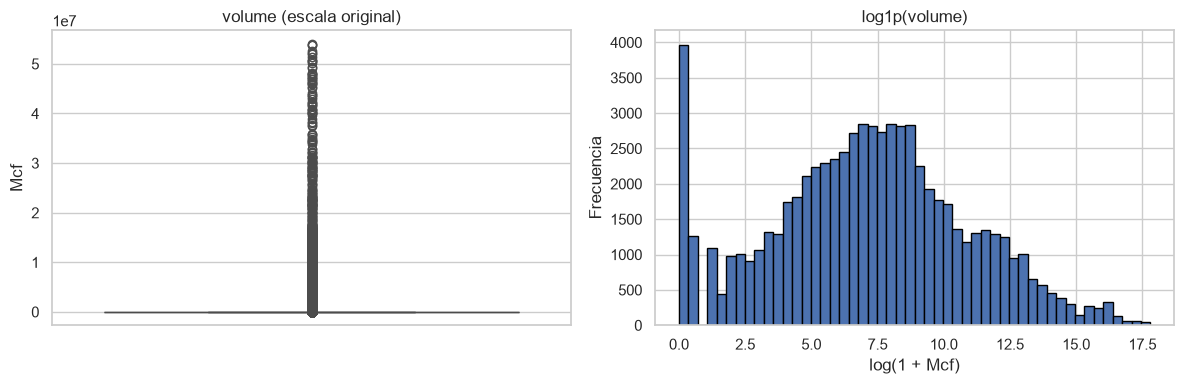

In [113]:
# Outliers de volume (único variable continua relevante)
q1 = gas_limpio['volume'].quantile(0.25)
q3 = gas_limpio['volume'].quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

gas_limpio['es_outlier_volume'] = (gas_limpio['volume'] < lim_inf) | (gas_limpio['volume'] > lim_sup)

print(f'Outliers: {gas_limpio["es_outlier_volume"].sum():,} '
      f'({gas_limpio["es_outlier_volume"].mean():.2%})')

# Distribución de outliers por categoría de disposición
print(pd.crosstab(gas_limpio['categoria'], gas_limpio['es_outlier_volume'], normalize='index').round(4))

# Gráficos: boxplot y histograma en escala log1p
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=gas_limpio['volume'], ax=axes[0], color='#55A868')
axes[0].set_title('volume (escala original)')
axes[0].set_ylabel('Mcf')

axes[1].hist(np.log1p(gas_limpio['volume']), bins=50, color='#4C72B0', edgecolor='black')
axes[1].set_title('log1p(volume)')
axes[1].set_xlabel('log(1 + Mcf)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

#### Interpretación

- IQR marca 12805 valores por encima del UP de 34117.375 como posibles outliers. El LB no importa porque no tenemos valores negativos en vol_pos.

El IQR utiliza un criterio más amplio, y probablemente esto se deba a que tenemos mucho sesgo en 'vol_pos', muchos valores pequeños y algunos muy grandes.


Un outlier no es necesariamente un error, por lo que no deberíamos de eliminar estos registros automáticamente, ya que podrían ser volúmenes reales y quitarlos afectaría a nuestro análisis del venteo y la quema de gas. Hay que investigar más, y decidir si conservar los datos en caso de que el contexto lo amerite.

Podemos interpretar:

- De las 12805 filas marcadas, la mayoría son de venta: 10594 (más del 80%). Hay 1948 de quema y 263 de venteo.
- El máximo es mucho mayor para venta que para quema o venteo, por eso la cola tan alta de los gráficos y del IQR.
- Solo estamos viendo los valores mayores a 34117.375 del UB del IQR en vol_pos, no tenemos prueba de que hayan errores, pueden ser registros válidos de gran volumen.

*Teóricamente estos datos oficiales de USA deberían de estar bien, pero habría que seguir analizando <---

*Habría que inspeccionar los registros más altos y sus fechas, ubicaciones y descripciones <---

### 3.7 - Encoding

In [114]:

UMBRAL_REGISTROS = 1500 #Lo colocamos para que cada estado onshore tenga suficientes observaciones
#para dar un coeficiente estable. Esto lo verificamos comprobando varios tipos de valores

ETIQ_OTROS = 'Otros estados'
ETIQ_INDIGENA = 'Tierra indígena (sin estado)'

# Estados onshore que no son tierra indígena
es_estado_onshore = (gas_limpio['land_category'].eq('Onshore')
                     & gas_limpio['land_class'].ne('Native American'))

#Selecciono las filas de la mascara y cuenta los registros que hay por estado
conteo_estados = gas_limpio.loc[es_estado_onshore, 'state'].value_counts()
#Filtramos los conteo y me quedo con aquellos que tengan al menos de 1500 registros y devuelve el nombre
estados_conservados = conteo_estados[conteo_estados >= UMBRAL_REGISTROS].index


In [115]:
#Construyo "ubicacion"
gas_limpio['ubicacion'] = np.select(
    [gas_limpio['land_category'].eq('Offshore'),
     gas_limpio['land_class'].eq('Native American'),
     es_estado_onshore & gas_limpio['state'].isin(estados_conservados)],
    [gas_limpio['offshore_region'], ETIQ_INDIGENA, gas_limpio['state']],
    default=ETIQ_OTROS
)
#Si el registro es offshore, toma ese
#Si es tierra indigena toma la etiqueta tierra indigena
#Si es onshore y no indigena toma el estaod conservado
#si no cumple ninguna toma etiq_otros

#Con el asster detenemos si la condicion es falsa y en la segunda fila comprobamos que no se duplico filas
assert gas_limpio['ubicacion'].notna().all(), 'Quedan valores sin ubicación'
assert len(gas_limpio) == 68964, 'Cambió el número de filas'

print('Estados conservados:', len(estados_conservados))
print('Estados agrupados en Otros:', sorted(conteo_estados[conteo_estados < UMBRAL_REGISTROS].index))
print(gas_limpio['ubicacion'].nunique(), 'niveles de ubicación')


Estados conservados: 11
Estados agrupados en Otros: ['AK', 'AL', 'ID', 'IL', 'KS', 'KY', 'MI', 'MS', 'NV', 'NY', 'OH', 'PA', 'SD', 'VA', 'WV']
16 niveles de ubicación


In [116]:
# Tabla de separacion
tabla_ub = (gas_limpio.groupby('ubicacion')['perdida']
            .agg(registros='size', tasa_perdida='mean')
            .sort_values('tasa_perdida'))
print(tabla_ub.round(4))
#Sirve para saber si la separacion es perfecta. Si es 0, los registros son ventas y el modelo de regresion
# intentaria


                              registros  tasa_perdida
ubicacion                                            
AR                                 2521        0.0956
Otros estados                      9670        0.1790
TX                                 4798        0.2113
OK                                 5927        0.2300
LA                                 2741        0.3112
Offshore Gulf                      1274        0.3940
CO                                 6511        0.3972
CA                                 2629        0.4131
UT                                 2989        0.4761
MT                                 4109        0.4845
WY                                10451        0.5835
NM                                 7163        0.5985
Tierra indígena (sin estado)       1536        0.6042
Offshore Pacific                    430        0.6186
Offshore Alaska                     373        0.6649
ND                                 5842        0.7412


Verificación de categorías sin separación

Antes de ajustar la regresión logística, se construyó una tabla con el número de registros y la proporción de pérdidas de cada categoría de ubicación. Esta tabla no es un resultado del análisis: es una comprobación de que el modelo puede estimar sus coeficientes.

La regresión logística calcula, para cada categoría, cuánto aumenta o disminuye la probabilidad de pérdida respecto de la categoría de referencia. Si una categoría tiene solo registros de venta (proporción 0) o solo registros de pérdida (proporción 1), el algoritmo intentaría asignarle una probabilidad extrema. En esos casos el coeficiente no tiene un valor finito y no puede interpretarse. A esta situación se la llama separación perfecta.

Por eso se verificó que ninguna categoría tuviera proporción 0 ni 1. La proporción más baja es 9,6 % (Arkansas) y la más alta 74,1 % (Dakota del Norte), por lo que todas las categorías permiten estimar un coeficiente.

La tabla también muestra el número de registros de cada categoría. Una proporción calculada sobre pocos registros es menos precisa, por lo que el tamaño de cada grupo se tuvo en cuenta al agrupar los estados con menos de 1.500 registros en "Otros estados".

In [117]:
# Variables predictores y de referencia
PREDICTORES_CAT = ['ubicacion', 'season']
OBJETIVO = 'perdida'
REFERENCIA = {'ubicacion': 'WY', 'season': 'Invierno'}

#Investigamos en el grupo y se menciona buena practica trabajar con copias para no alterar el df original
X = gas_limpio[PREDICTORES_CAT].copy()
y = gas_limpio[OBJETIVO].copy()

#Verificaciones de X
assert X.notna().all().all(), 'Quedan NaN en las predictoras'
assert REFERENCIA['ubicacion'] in X['ubicacion'].unique(), 'Referencia de ubicación inexistente'

#Funcion de referencia
def con_referencia(serie, ref):
    """La referencia va primero: OneHotEncoder(drop='first') elimina ese nivel."""
    return [ref] + [n for n in sorted(serie.unique()) if n != ref]

#Fijamos la categoria para garantizar que la referencia siempre sea la misma
categorias = [
    con_referencia(X['ubicacion'], REFERENCIA['ubicacion']),
    con_referencia(X['season'], REFERENCIA['season']),
]


In [118]:
# Codificador one-hot dentro del Pipeline 
codificador = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(categories=categorias,
                                 drop='first',
                                 handle_unknown='ignore',
                                 sparse_output=False), PREDICTORES_CAT)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

modelo_lr = Pipeline([
    ('encoding', codificador),
    ('clf', LogisticRegression(max_iter=1000))
])


In [119]:
# Verificación de forma y dependencias 
X_codificada = codificador.fit_transform(X)
rango = np.linalg.matrix_rank(np.column_stack([np.ones(len(X_codificada)), X_codificada]))

print('Dimensiones X codificada:', X_codificada.shape)
print('Rango con intercepto:', rango, '| Esperado sin dependencias:', X_codificada.shape[1] + 1)
print('Referencias:', REFERENCIA)
print('Proporción de perdida (registros):', round(y.mean(), 4))
print(list(codificador.get_feature_names_out()))

Dimensiones X codificada: (68964, 18)
Rango con intercepto: 19 | Esperado sin dependencias: 19
Referencias: {'ubicacion': 'WY', 'season': 'Invierno'}
Proporción de perdida (registros): 0.4197
['ubicacion_AR', 'ubicacion_CA', 'ubicacion_CO', 'ubicacion_LA', 'ubicacion_MT', 'ubicacion_ND', 'ubicacion_NM', 'ubicacion_OK', 'ubicacion_Offshore Alaska', 'ubicacion_Offshore Gulf', 'ubicacion_Offshore Pacific', 'ubicacion_Otros estados', 'ubicacion_TX', 'ubicacion_Tierra indígena (sin estado)', 'ubicacion_UT', 'season_Otoño', 'season_Primavera', 'season_Verano']


In [120]:
def tabla_proporciones(df, grupo):
    t = (
        df.assign(vol_perdida=df['volume'].where(df['perdida'] == 1, 0))
          .groupby(grupo)
          .agg(registros=('perdida', 'size'),
               registros_perdida=('perdida', 'sum'),
               vol_total=('volume', 'sum'),
               vol_perdida=('vol_perdida', 'sum'))
    )
    t['prop_registros'] = t['registros_perdida'] / t['registros']
    # Evita la división 0/0 (por ejemplo, estados sin volumen)
    t['prop_volumen'] = (t['vol_perdida'] / t['vol_total']).where(t['vol_total'] > 0)
    return t.sort_values('prop_volumen', ascending=False)

for grupo in ['season', 'land_class', 'offshore_region', 'state', 'ubicacion']:
    print(f'\n--- Por {grupo} ---')
    print(tabla_proporciones(gas_limpio, grupo).round(4))

# Desglose de "Otros estados" (el grupo esconde estados con comportamientos muy distintos)
otros = gas_limpio[gas_limpio['ubicacion'].eq(ETIQ_OTROS)]
print('\n--- Desglose de Otros estados ---')
print(tabla_proporciones(otros, 'state').round(4))


--- Por season ---
           registros  registros_perdida   vol_total  vol_perdida  \
season                                                             
Verano         16636               7026  4626173414    136069676   
Otoño          16567               6974  4660298234    134239898   
Invierno       17590               7338  4964455208    135371631   
Primavera      18171               7609  5185129114    134485058   

           prop_registros  prop_volumen  
season                                   
Verano             0.4223        0.0294  
Otoño              0.4210        0.0288  
Invierno           0.4172        0.0273  
Primavera          0.4187        0.0259  

--- Por land_class ---
                   registros  registros_perdida    vol_total  vol_perdida  \
land_class                                                                  
Native American         1536                928   1511828661    160558273   
Federal                63486              26225  17430821552    

Con este ultimo codigo buscamos ver y dimensionar que para cada grupo, cuantos registros hay, cuantos son perdida, cuanto es el volumen total y cuanto volumen perdemos
Queremos saber esto y la perdida porque hay valores de gases que se venden, que se queman o se ventean. 

No el motivo por el cual se realizo pero es un dato util ya que queremos resolver una pregunta de impacto ambiental. Estas formas numericas de representar nos permiten a nosotros tener una magnitud de lo que sucede


#### Explicacion del encoding

##### Objetivo

El modelo de clasificación requiere variables numéricas, por lo que las variables categóricas se transforman mediante **codificación one-hot**: cada nivel de una variable se convierte en una columna que toma valor 1 si el registro pertenece a ese nivel y 0 en caso contrario.

##### Variables candidatas y decisión

Se partió de cuatro variables que describen la ubicación y el momento del registro:

- `state`: estado de la producción. Tiene 28 niveles, incluidas las categorías de faltante etiquetadas.
- `offshore_region`: región offshore (Alaska, Golfo, Pacífico) o "No aplica (onshore)".
- `land_class`: tipo de tierra (Federal, Mixed Exploratory, Native American).
- `season`: época del año (Invierno, Primavera, Verano, Otoño).

Las variables `land_category` (equivalente a `offshore_region`), `county` (alta cardinalidad) y `fips_code` (dañado por conversiones previas) se excluyeron como predictores.

##### Solución: variable única de ubicación

Se construyó una variable `ubicacion` con categorías mutuamente excluyentes, donde cada registro pertenece a una sola categoría:

1. **Estados onshore con al menos 1.500 registros** (11 niveles): se conservan con su código de estado.
2. **Otros estados onshore** (15 estados con menos de 1.500 registros): se agrupan en "Otros estados".
3. **Regiones offshore** (Alaska, Golfo, Pacífico): se conservan como categorías propias.
4. **Tierra indígena (sin estado)**: una categoría propia.

Esto da 16 niveles. La matriz codificada tiene 18 columnas (15 de `ubicacion` y 3 de `season`) y rango 19, igual al número de columnas más el intercepto. Con esto desaparecen las dependencias.

##### Criterio del umbral de 1.500 registros

El umbral busca que cada categoría onshore tenga suficientes observaciones para estimar un coeficiente estable. Con 1.500 registros se conservan 11 estados. Tras la agrupación, ningún nivel tiene una tasa de pérdida de 0 % ni de 100 %. El umbral es una decisión y no un resultado: otro umbral daría otra agrupación y debe reportarse como tal.

Las categorías offshore no se sometieron al umbral debido a que la cantidad de registros que mantenemos son menores, aun asi queremos dejarlas.

##### Codificación one-hot y eliminación de referencia

Las categorías son nominales, sin orden natural. Una codificación numérica (1, 2, 3, 4) haría que el modelo supusiera distancias y órdenes que no existen en los datos. Por eso se usa one-hot.

En la regresión logística se elimina una categoría por variable (`drop='first'`). Si no se elimina, las columnas son redundantes. Los coeficientes se interpretan respecto a la categoría de referencia, que se fija explícitamente y no por orden alfabético:

- `ubicacion`: WY, por ser el estado con más registros entre los conservados. Su estimación es la más estable.
- `season`: Invierno.

##### Por qué `season` y no `month`

La pregunta de investigación menciona "época del año", que corresponde a la estación. `month` tiene 12 niveles y `season` es una agrupación de `month`, por lo que incluir ambas duplicaría información. `month` queda reservado como análisis mas profundo

Basicamente porque queremos evitar duplicar tante informacion.

##### Pipeline y ColumnTransformer

El codificador se integra en un `Pipeline` junto con el clasificador. Durante la validación cruzada, cada partición aprende sus categorías solo con sus datos de entrenamiento. Si el codificador se ajustara sobre todo el conjunto antes de partirlo, la información de validación influiría en el modelo y las métricas quedarían infladas.

El parámetro `handle_unknown='ignore'` evita errores si aparece en validación una categoría ausente en entrenamiento: en ese caso, el registro queda con ceros en todas las columnas de esa variable.

##### Verificación

- La matriz codificada tiene dimensiones (68.964, 18) y rango con intercepto igual a 19.
- Ningún nivel de `ubicacion` tiene tasa de pérdida de 0 % ni de 100 %.
- La proporción de pérdida por registros es 0,4197.


## 4- Analisis de Algoritmos


In [121]:
# X e y salen de la sección3.7 (X = ubicacion y season; y = perdida)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f'Entrenamiento: {X_train.shape[0]} registros')
print(f'Prueba:        {X_test.shape[0]} registros  (no se usa hasta el final)')
print(f'Proporción de pérdida en train: {y_train.mean():.4f}')
print(f'Proporción de pérdida en test:  {y_test.mean():.4f}')
print(f'Piso por exactitud (clase mayoritaria): {1 - y_train.mean():.4f}')

Entrenamiento: 51723 registros
Prueba:        17241 registros  (no se usa hasta el final)
Proporción de pérdida en train: 0.4197
Proporción de pérdida en test:  0.4198
Piso por exactitud (clase mayoritaria): 0.5803


### 4.1 - Algoritmo y linea base

In [122]:
#Divido el entrenamiento en 5 partes. Una funciona como validacion y el resto como entrenamiento
#Asi tengo 5 estimaciones
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

#Metricas

scoring = {
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
    'recall': 'recall',
}
#acc proporcion de aciertos
#roc_auc que tan bien ordena el modelo el registro de perdida por encima de ventas
#average precision es el area bajo la curva de presicion recall
#recall proporcion de perdidas que detecta el modelo


# Línea base: score constante igual a la proporción de cada clase
baseline = Pipeline([
    ('encoding', clone(codificador)),
    ('clf', DummyClassifier(strategy='prior'))
])

modelos = {'Dummy (línea base)': baseline, 'Regresión Logística': modelo_lr}


In [123]:
#Validacion cruzada 
metricas_cv = {}
for nombre, modelo in modelos.items():
    res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring)
    metricas_cv[nombre] = {m: res[f'test_{m}'] for m in scoring}

#Tabla resumen
resumen = pd.DataFrame({
    m: {nombre: metricas_cv[nombre][m].mean() for nombre in modelos}
    for m in scoring
}).T
resumen.columns = ['Dummy (línea base)', 'Regresión Logística']
resumen['Mejora sobre el piso'] = resumen['Regresión Logística'] - resumen['Dummy (línea base)']

print('Validación cruzada (5 particiones, solo entrenamiento)')
print(resumen.round(4).to_string())

Validación cruzada (5 particiones, solo entrenamiento)
          Dummy (línea base)  Regresión Logística  Mejora sobre el piso
accuracy              0.5803               0.6748                0.0945
roc_auc               0.5000               0.7214                0.2214
pr_auc                0.4197               0.6199                0.2001
recall                0.0000               0.5566                0.5566


El código usa return_train_score=True para mostrar las dos columnas que enseña la guía: rendimiento sobre datos nuevos (validación) y sobre entrenamiento. Si la diferencia entre ambas es grande, hay sobreajuste.

Qué verificar:

El dummy debe dar ROC-AUC de 0,5000, PR-AUC cerca de 0,4197, exactitud de 0,5803 y recall de 0,0000. Si no es así, hay un error en el pipeline.

La regresión logística debe superar al dummy en ROC-AUC y PR-AUC. 

### ¿Más datos mejoran el modelo?

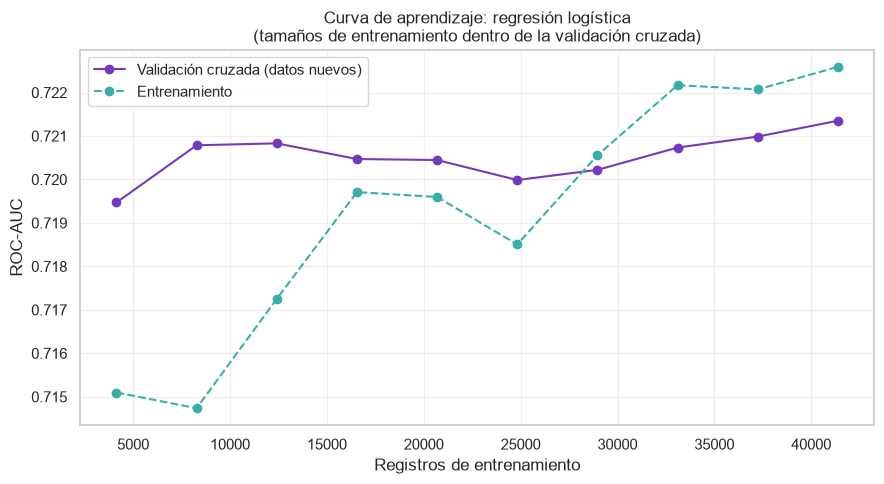

In [124]:
tamaños, sc_train, sc_val = learning_curve(
    modelo_lr, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv,
    scoring='roc_auc'
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tamaños, sc_val.mean(axis=1), 'o-', color='#753ABC',
        label='Validación cruzada (datos nuevos)')
ax.plot(tamaños, sc_train.mean(axis=1), 'o--', color='#3AAFA9',
        label='Entrenamiento')
ax.set_xlabel('Registros de entrenamiento')
ax.set_ylabel('ROC-AUC')
ax.set_title('Curva de aprendizaje: regresión logística')
ax.legend()
ax.grid(alpha=0.3)
ax.set_title('Curva de aprendizaje: regresión logística\n'
             '(tamaños de entrenamiento dentro de la validación cruzada)')
plt.tight_layout()
plt.show()

Con el learning curve repito el entrenamiento pero con distintos tamaños de datos

Respecto al grafico, la curva violeta nos indica los datos nuevos. Es decir, que tan bien predice el modelo los datos que no vio (es la que importa)

La linea verde punteada (entrenamiento) indica que tan bien ajusta los datos con los que entreno

El grafico nos permite concluir:

La validación sube muy poco. Empieza en 0,7195 con unos 4.000 registros y termina en 0,7214 con unos 41.000. 
Las dos líneas se acercan. Con más datos, el entrenamiento baja a la misma zona que la validación. Eso indica que el modelo no memoriza: se comporta igual con datos viejos que con datos nuevos.
La línea de entrenamiento oscila al principio. Con pocos datos, el ajuste depende mucho de qué registros caen en la muestra. 

Si la validación ya no sube con más datos, el problema no es la cantidad de registros. Lo que limita al modelo es la información de sus variables: solo tiene la ubicación y la estación.

#### Resumen de lo realizado

##### Objetivo

Evaluar si la regresión logística aprende la asociación entre ubicación, época del año y el registro de pérdida (venteo o quema frente a venta), y si lo hace mejor que una línea base. 

##### Partición estratificada

Se separan 25 % de los registros como conjunto de prueba (17.241) y 75 % como entrenamiento (51.723). La partición es estratificada por `perdida`, de modo que la proporción de registros de pérdida es casi igual en ambos conjuntos (cerca de 0,42). Se fija `random_state=42` para que el resultado sea reproducible. El 25 % es el valor habitual del curso.

##### Validación cruzada

Sobre el conjunto de entrenamiento se aplica validación cruzada estratificada de 5 particiones (`StratifiedKFold`). En cada partición, el codificador se reajusta solo con los datos de entrenamiento de esa partición, porque está dentro de un `Pipeline`. Así, la información de validación no influye en el modelo.

##### Línea base

Se usa `DummyClassifier(strategy='prior')` como piso. Este modelo asigna a cada registro la proporción de la clase, por lo que su ROC-AUC es 0,5 y su PR-AUC es igual a la prevalencia de pérdida (cerca de 0,42).

##### Curva de aprendizaje

Se calcula la curva de aprendizaje de la regresión logística con tamaños crecientes del conjunto de entrenamiento. Sirve para saber si conseguir más registros mejoraría el rendimiento sobre datos nuevos. Si la curva se estabiliza con pocos datos, el límite del modelo está en las variables disponibles y no en el tamaño de la muestra.

##### Limitación de independencia

Los registros de una misma ubicación en meses consecutivos no son independientes entre sí. La partición aleatoria puede hacer que registros muy parecidos caigan en entrenamiento y prueba, lo que inflaría las métricas. Como verificación complementaria, se evaluará una partición temporal (entrenar hasta 2023 y probar en 2024-2025).

##### Limitación de la agrupación

La decisión de agrupar los estados con menos de 1.500 registros en "Otros estados" se tomó con conteos del dataset completo. No usa la variable objetivo, pero sí se hizo antes de la partición. Por eso el umbral debe reportarse como decisión metodológica y no como resultado.

## 4.2 - Random Forest

In [125]:
#Codificador para el random forest
codificador_rf = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(categories=categorias,
                                 handle_unknown='ignore',
                                 sparse_output=False), PREDICTORES_CAT)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

#Modelo de Random Forest
modelo_rf = Pipeline([
    ('encoding', codificador_rf),
    ('clf', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=50,      # evita hojas con pocos registros, que memorizan
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])


Es el mismo codificador de la regresion logistica con la diferencia de que ya no tenemos el drop firt. Esto porque RL necesita quitarlo, si no es asi es redundante

Como Random Forest toma decisiones mediantes preguntas y respuestas y se va dividiendo en ramas no necesita eliminar esa columna. Si la eliminamos quitamos informacion el modelo

Respecto al modelo random Forest decidimos no graficarlo ya que entrenamos 300 arboles, con cada hoja de 50 registros 

Por ahora fijamos estos hiperparametros a mano. Mas adelante los optimizaremos con optuna


In [126]:
# 2) Tasa por celda: una probabilidad independiente por cada combinación ubicación × estación
def combinar_celda(df):
    return (df['ubicacion'].astype(str) + ' | ' + df['season'].astype(str)).to_frame('celda')

modelo_celda = Pipeline([
    ('celda', FunctionTransformer(combinar_celda)),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ('clf', LogisticRegression(max_iter=1000))
])


Combinamos ubicacion y season porque tuvimos la siguiente duda: Si conocemos la perdida en la combinacion de ubbicacion y season ¿Que tan bien podemos predecir? Asi que nos viene bien como referencia de maximo rendimiento de nuestro modelo. Basicamente le damos un techo

De esta forma podemos trabajar con un "piso" (Modelo Dummy) y con un techo (el que explicamos)

In [127]:
# Comparación con la misma validación cruzada usada hasta ahora
modelos_comp = {
    'Dummy (línea base)': baseline,
    'Regresión Logística': modelo_lr,
    'Random Forest': modelo_rf,
    'Tasa por celda (ubicación × estación)': modelo_celda, #Aca colocamos el techo
}

filas = {} #Validacion cruzada
for nombre, modelo in modelos_comp.items():
    res = cross_validate(modelo, X_train, y_train, cv=cv,
                         scoring=scoring, return_train_score=True)
    fila = {m: res[f'test_{m}'].mean() for m in scoring}
    fila['roc_auc_desvio'] = res['test_roc_auc'].std()
    fila['roc_auc_train'] = res['train_roc_auc'].mean()
    fila['pr_auc_train'] = res['train_pr_auc'].mean()
    filas[nombre] = fila

resumen_modelos = pd.DataFrame(filas).T
resumen_modelos


,accuracy,roc_auc,pr_auc,recall,roc_auc_desvio,roc_auc_train,pr_auc_train
Dummy (línea base),0.5803,0.5000,0.4197,0.0000,0.0000,0.5000,0.4197
Regresión Logística,0.6748,0.7214,0.6199,0.5566,0.0057,0.7226,0.6205
Random Forest,0.6745,0.7199,0.6159,0.5590,0.0055,0.7233,0.6216
Tasa por celda (ubicación × estación),0.6739,0.7195,0.6145,0.5654,0.0056,0.7234,0.6219


In [128]:
# Diferencia de cada modelo frente a la regresión logística

ref_lr = resumen_modelos.loc['Regresión Logística']
resumen_modelos['roc_auc vs LR'] = resumen_modelos['roc_auc'] - ref_lr['roc_auc']
resumen_modelos['pr_auc vs LR'] = resumen_modelos['pr_auc'] - ref_lr['pr_auc']

print('Validación cruzada (5 particiones, solo entrenamiento)')
print(resumen_modelos.round(4).to_string())

Validación cruzada (5 particiones, solo entrenamiento)
                                       accuracy  roc_auc  pr_auc  recall  roc_auc_desvio  roc_auc_train  pr_auc_train  roc_auc vs LR  pr_auc vs LR
Dummy (línea base)                       0.5803   0.5000  0.4197  0.0000          0.0000         0.5000        0.4197        -0.2214       -0.2001
Regresión Logística                      0.6748   0.7214  0.6199  0.5566          0.0057         0.7226        0.6205         0.0000        0.0000
Random Forest                            0.6745   0.7199  0.6159  0.5590          0.0055         0.7233        0.6216        -0.0014       -0.0039
Tasa por celda (ubicación × estación)    0.6739   0.7195  0.6145  0.5654          0.0056         0.7234        0.6219        -0.0019       -0.0053


In [129]:
param_grid = {'clf__C': [0.01, 0.1, 1, 10, 100]}


#Busco todas las combinaciones de param_grid y hace una validacion cruzada y promedia con roc auc
busqueda_lr = GridSearchCV(
    modelo_lr,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True   # necesario para ver la brecha train/validación
)
busqueda_lr.fit(X_train, y_train)

print('Mejor C:', busqueda_lr.best_params_['clf__C'])
print(f'Mejor ROC-AUC (validación): {busqueda_lr.best_score_:.4f}')


Mejor C: 0.1
Mejor ROC-AUC (validación): 0.7214


In [130]:
#Presento los datos y las validaciones
resultados_C = pd.DataFrame(busqueda_lr.cv_results_)[
    ['param_clf__C', 'mean_test_score', 'std_test_score', 'mean_train_score']
].rename(columns={'param_clf__C': 'C', 'mean_test_score': 'roc_auc_val',
                  'std_test_score': 'desvio', 'mean_train_score': 'roc_auc_train'})
print(resultados_C.round(4).to_string(index=False))

       C  roc_auc_val  desvio  roc_auc_train
  0.0100       0.7211  0.0057         0.7221
  0.1000       0.7214  0.0058         0.7226
  1.0000       0.7214  0.0057         0.7226
 10.0000       0.7213  0.0056         0.7226
100.0000       0.7213  0.0056         0.7226


### Comparación de modelos, selección del modelo y ajuste de C

#### ¿Que es C? Explicacion

La regresión logística calcula un coeficiente para cada variable, que indica cuánto pesa en la predicción. Por ejemplo, si el coeficiente de Dakota del Norte es grande, ese estado pesa mucho en que el registro sea pérdida.

C controla cuánto dejamos que esos coeficientes crezcan. Es una especie de freno.

C chico (por ejemplo, 0,01): el freno es fuerte. Los coeficientes no pueden crecer mucho y quedan cerca de cero. El modelo es más conservador.
C grande (por ejemplo, 100): el freno es casi nulo. Los coeficientes pueden tomar cualquier valor que mejor se ajuste a los datos.

¿Porque lo vemos? Si tenemos pocos datos sobre un estado raro y todos son perdidas. Si el modelo ajusta el coeficiente sin limites le asignara un valor grande ya que todosn son perdidas. Este valor grande no es util para predecir registros nuesvos de ese estados

Este "freno" evita ese exceso. Con C chico, el modelo prefiere coeficientes moderados, aunque se ajusten un poco menos a los datos de entrenamiento. Eso puede mejorar la predicción sobre datos nuevos.

En lo personal lo entiendo como algo similar al min registros por hoja de un Random Forest

#### Objetivo

Determinar si la regresión logística, puede mejorarse con modelos que capten interacciones entre ubicación y época del año, y elegir el modelo final sin usar el conjunto de prueba.

#### Modelos comparados

Se compararon cuatro modelos con la misma partición de entrenamiento y la misma validación cruzada estratificada de 5 particiones:

1. **Línea base (`DummyClassifier`):** asigna a cada registro la proporción de su clase. Establece el piso de comparación. Se usa `prior` y no `most_frequent` porque este último devuelve una probabilidad constante de 1 a una sola clase, lo que deja el ROC-AUC fijo en 0,5 por construcción.
2. **Regresión logística:** modelo sobre `ubicacion` y `season`, con codificación one-hot, referencias explícitas (WY e Invierno) y `C = 1`.
3. **Random Forest:** 300 árboles con `min_samples_leaf = 50`, sin eliminar categorías de referencia. Puede captar interacciones sin que se definan de antemano. Los hiperparámetros no fueron optimizados.
4. **Tasa por celda (`Techo`):** regresión logística sobre la combinación `ubicacion × season`. Representa una referencia de techo.

#### Resultados de validación cruzada

(tabla del codigo de mas arriba)

| Modelo | Exactitud | ROC-AUC | PR-AUC | Recall (pérdida) | Desvío ROC-AUC | ROC-AUC entrenamiento |
|---|---|---|---|---|---|---|
| Dummy (línea base) | 0,5803 | 0,5000 | 0,4197 | 0,0000 | 0,0000 | 0,5000 |
| **Regresión logística** | **0,6748** | **0,7214** | **0,6199** | 0,5566 | 0,0057 | 0,7226 |
| Random Forest | 0,6745 | 0,7199 | 0,6159 | 0,5590 | 0,0055 | 0,7233 |
| Tasa por celda | 0,6739 | 0,7195 | 0,6145 | 0,5654 | 0,0056 | 0,7234 |


#### Interpretación

**Los modelos no lineales no mejoran a la regresión logística.** Las diferencias en ROC-AUC (−0,0014 y −0,0019) y en PR-AUC (−0,0039 y −0,0053) son menores que el desvío estándar entre particiones (0,0057). Ningún modelo alternativo supera a la regresión logística.

**Las interacciones entre ubicación y época del año no aportan información relevante.** La tasa por celda, que es la referencia de techo para estas dos variables, logra el mismo rendimiento que el modelo. Por lo tanto, el límite del modelo está en la información disponible y no en la forma funcional.

**Hay una brecha entre entrenamiento y validación, pero es pequeña.** La brecha en ROC-AUC es de 0,0012 para la regresión logística, 0,0034 para el Random Forest y 0,0039 para la tasa por celda. Los dos modelos no lineales tienen una brecha algo mayor, lo que indica un leve sobreajuste que no se traduce en mejor rendimiento sobre datos nuevos.

#### Selección del modelo final

Se elige la **regresión logística** por tres motivos:

- Su rendimiento es igual al de los modelos no lineales dentro del margen de error de la validación.
- Es el modelo más simple de los comparados.
- Tiene la menor brecha entre entrenamiento y validación.

#### Ajuste del parámetro de regularización C

Se evaluaron valores de `C` entre 0,01 y 100 con `GridSearchCV`, usando la misma validación cruzada y ROC-AUC como métrica:

(tabla del codigo)

| C | ROC-AUC validación | Desvío | ROC-AUC entrenamiento |
|---|---|---|---|
| 0,01 | 0,7211 | 0,0057 | 0,7221 |
| 0,1 | 0,7214 | 0,0058 | 0,7226 |
| 1 | 0,7214 | 0,0057 | 0,7226 |
| 10 | 0,7213 | 0,0056 | 0,7226 |
| 100 | 0,7213 | 0,0056 | 0,7226 |

El valor con mayor ROC-AUC de validación fue `C = 0,1`, pero la diferencia respecto de `C = 1` es menor a 0,0001, mientras que el desvío entre particiones es de 0,0057. Ninguna diferencia entre valores de `C` es distinguible de cero. Por simplicidad y por aplicar el criterio definido previamente, se mantuvo `C = 1` (valor por defecto).

Este resultado es coherente con la curva de aprendizaje: el modelo no sobreajusta y, con 18 variables binarias y más de 50.000 registros, la penalización casi no modifica los coeficientes.


# 5 - Evaluacion del modelo Final

## 5.1 - Entrenamiento y metricas de prueba

In [131]:
# Modelo final: regresión logística con C = 1, ajustada solo con el entrenamiento
modelo_final = clone(modelo_lr)
modelo_final.fit(X_train, y_train)

# Única predicción sobre el conjunto de prueba
y_test_prob = modelo_final.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= 0.5).astype(int)   # umbral por defecto no ajustado
#Si la probabilidad da mayor a 0,5 lo toma como perdida (1)


metricas_test = {
    'Exactitud': accuracy_score(y_test, y_test_pred),
    'ROC-AUC': roc_auc_score(y_test, y_test_prob),
    'PR-AUC': average_precision_score(y_test, y_test_prob),
    'Recall (pérdida)': recall_score(y_test, y_test_pred),
}
#Roc aucc y pr auc sobre la probabilidad ya que trabajan con ella


# Comparación con validación cruzada (estabilidad de la estimación)
comparacion = pd.DataFrame({
    'Validación cruzada': {'Exactitud': 0.6748, 'ROC-AUC': 0.7214,
                           'PR-AUC': 0.6199, 'Recall (pérdida)': 0.5566},
    'Prueba': metricas_test
}) #Cambiar esto despues ya que la puse a mano. Deberia hacer referencia a la tabla
# asi el valor se me actualiza

comparacion['Diferencia'] = comparacion['Prueba'] - comparacion['Validación cruzada']
print(comparacion.round(4).to_string())

print()
print(f'Prevalencia de pérdida en prueba: {y_test.mean():.4f}')
print()
print(classification_report(y_test, y_test_pred,
                            target_names=['Venta', 'Pérdida'], digits=4))

                  Validación cruzada  Prueba  Diferencia
Exactitud                     0.6748  0.6748     -0.0000
ROC-AUC                       0.7214  0.7229      0.0015
PR-AUC                        0.6199  0.6207      0.0008
Recall (pérdida)              0.5566  0.5628      0.0062

Prevalencia de pérdida en prueba: 0.4198

              precision    recall  f1-score   support

       Venta     0.7050    0.7558    0.7295     10004
     Pérdida     0.6251    0.5628    0.5923      7237

    accuracy                         0.6748     17241
   macro avg     0.6650    0.6593    0.6609     17241
weighted avg     0.6714    0.6748    0.6719     17241



## 5.2 - Matriz de curva y confusion

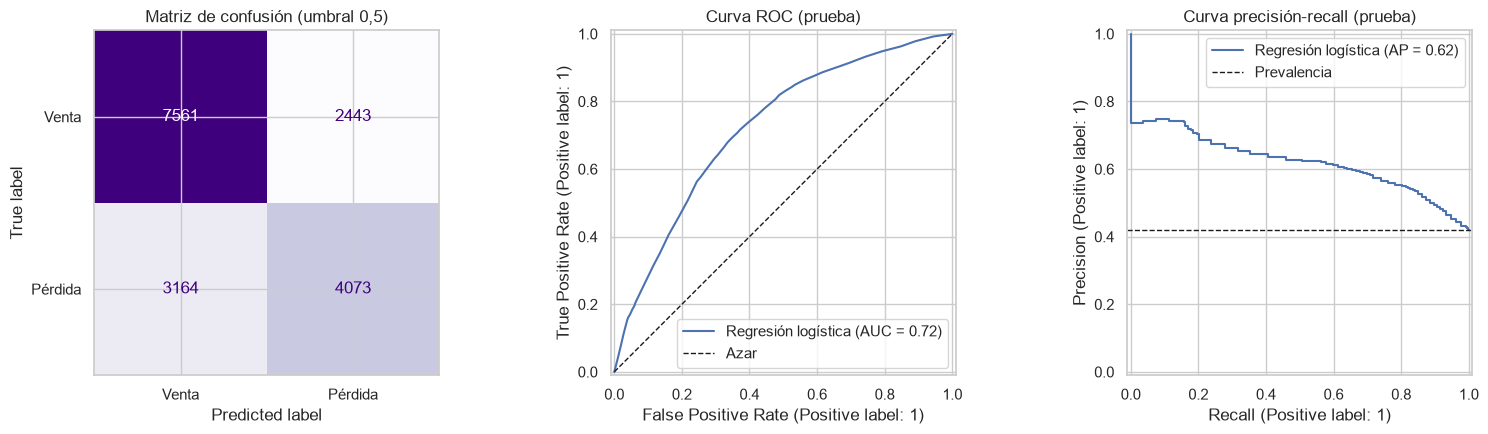

In [132]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_test_pred),
                       display_labels=['Venta', 'Pérdida']
                       ).plot(ax=axes[0], cmap='Purples', colorbar=False)
axes[0].set_title('Matriz de confusión (umbral 0,5)')

RocCurveDisplay.from_predictions(y_test, y_test_prob, ax=axes[1],
                                 name='Regresión logística')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Azar')
axes[1].set_title('Curva ROC (prueba)')
axes[1].legend()

PrecisionRecallDisplay.from_predictions(y_test, y_test_prob, ax=axes[2],
                                        name='Regresión logística')
axes[2].axhline(y_test.mean(), color='k', ls='--', lw=1, label='Prevalencia')
axes[2].set_title('Curva precisión-recall (prueba)')
axes[2].legend()

plt.tight_layout()
plt.show()

Matriz de confusion:

7561 ventas correctamente clasificadas por el modelo

2443 ventas marcadas como perdidas, falsos positivos, el modelo dice que es perdida pero es una venta

3164: perdidas marcadas como ventas, falsos negativos, el modelo no detecto una perdida

4073: perdidas correctamente detectadas, el modelo predijo perdida y el registro realmente era venteo o quema

El modelo detecta 4073 perdidas de las 7237 reales, o sea que deja sin detectar mas del 40%

De los 6516 registros que son perdidas, 4073 si lo eran, precision del 60%

Clasifica al rededor del 67% de los registros

Todo esto con umbral del 0,5, o sea probabilidad de perdida de al menos 50%: si no es perdida, predice venta. Valor predeterminado, no necesariamente el mejor.

Paso 3 - Intervalo de confianza por Bootstrap

In [133]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
p_arr = np.asarray(y_test_prob)
n = len(y_arr)

boot_auc, boot_pr = [], []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    if len(np.unique(y_arr[idx])) < 2:   # evita remuestras con una sola clase
        continue
    boot_auc.append(roc_auc_score(y_arr[idx], p_arr[idx]))
    boot_pr.append(average_precision_score(y_arr[idx], p_arr[idx]))

ic_auc = np.percentile(boot_auc, [2.5, 97.5])
ic_pr = np.percentile(boot_pr, [2.5, 97.5])

print(f"ROC-AUC prueba: {metricas_test['ROC-AUC']:.4f}  IC 95 %: [{ic_auc[0]:.4f}, {ic_auc[1]:.4f}]")
print(f"PR-AUC prueba:  {metricas_test['PR-AUC']:.4f}  IC 95 %: [{ic_pr[0]:.4f}, {ic_pr[1]:.4f}]")

ROC-AUC prueba: 0.7229  IC 95 %: [0.7151, 0.7301]
PR-AUC prueba:  0.6207  IC 95 %: [0.6092, 0.6329]


### Resumen

#### Objetivo

Estimar el rendimiento del modelo final (regresión logística con `C = 1`) sobre datos que no se usaron en ninguna decisión previa, y responder la pregunta de investigación.

#### Rendimiento sobre el conjunto de prueba

El modelo se ajustó con los 51.723 registros de entrenamiento y se evaluó una sola vez sobre los 17.241 registros de prueba. La prevalencia de pérdida es 0,4198 en prueba y 0,4197 en entrenamiento.

| Métrica | Validación cruzada | Prueba | Diferencia |
|---|---|---|---|
| Exactitud | 0,6748 | 0,6748 | 0,0000 |
| ROC-AUC | 0,7214 | 0,7229 | +0,0015 |
| PR-AUC | 0,6199 | 0,6207 | +0,0008 |
| Recall (pérdida) | 0,5566 | 0,5628 | +0,0062 |

Las métricas sobre prueba coinciden con las de validación cruzada, lo que confirma que la estimación de rendimiento es estable.

**Intervalos de confianza (bootstrap, 1.000 remuestras del conjunto de prueba):**
- ROC-AUC: 0,7229 (IC 95 %: 0,7151 a 0,7301).
- PR-AUC: 0,6207 (IC 95 %: 0,6092 a 0,6329).

#### Matriz de confusión y reporte de clasificación (umbral 0,5)

| Clase real | Predicha venta | Predicha pérdida |
|---|---|---|
| Venta (10.004) | 7.561 | 2.443 |
| Pérdida (7.237) | 3.164 | 4.073 |

- **Venta:** precisión 0,705, recall 0,756.
- **Pérdida:** precisión 0,625, recall 0,563, F1 0,592.

El modelo identifica el 56 % de los registros de pérdida. Los 3.164 falsos negativos representan pérdidas que no se detectan con este umbral. El umbral de 0,5 es el valor por defecto y no se ajustó con el conjunto de prueba.

#### Curvas ROC y precisión-recall

La curva ROC queda por encima de la diagonal de azar, con AUC de 0,72. La curva precisión-recall queda por encima de la prevalencia (0,42) en todo el rango de recall, con AP de 0,62.
